In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.model_selection import learning_curve
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_curve
from sklearn.metrics import precision_recall_curve

from astroML.classification import GMMBayes
from astroML.utils import split_samples, completeness_contamination

import h5py

## Time to get your hands dirty! Can a computer learn if we're going to detect gravitational waves?
 
**The goal here is to machine-learn the LIGO detectability: can we *predict* if a gravitational-wave source will be detected?**  

[This dataset](https://github.com/dgerosa/pdetclassifier/releases/download/v0.2/sample_2e7_design_precessing_higherordermodes_3detectors.h5) contains simulated gravitational-wave signals from merging black holes (careful the file size is >1 GB). If you've never seen them, the [.h5 format](https://en.wikipedia.org/wiki/Hierarchical_Data_Format) is a highly optimized storage strategy for large datasets. It's amazing. In python, you can read it with `h5py`.

In particular, each source has the following features:
- `mtot`: the total mass of the binary
- `q`: the mass ratio
- `chi1x`, `chi1y`, `chi1z`, `chi2x`, `chi2y`, `chi2z`: the components of the black-hole spins in a suitable reference frame.
- `ra`, `dec`: the location of the source in the sky
- `iota`: the inclination of the orbital plane'
- `psi`: the polarization angle (gravitational waves have two polarization states much like light)
- `z`: the redshift

The detectability is defined using the `snr` (signal-to-noise ratio) computed with a state-of-the-art model of the LIGO/Virgo detector network. Some (many?) of you will have studied this in the gravitational-wave class; [see here](https://arxiv.org/abs/1908.11170) for a nice write-up. All you need to know now is that we threshold the `snr` values and assume that LIGO will (not) see a source if `snr`>12 (`snr`<12). The resulting 0-1 labels are reported in the `det` attribute in the dataset.

Today's task is to train a classifier (you decide which one!) and separate sources that are detectables from those that aren't. 

Be creative! This is a challenge! Let's see who gets the  higher completeness and/or the smaller contamination (on a validation set, of course, careful with overfitting here).

*Tips*:
- You can downsample the data for debugging purposes
- You can also use only some of the features.
- Plot ROC curves
- **Important** Don't use `snr` as feature in your classifer (that's the answer...)


### Other ideas (optional)

- Using the same data, we could run a regressor on `snr` instead of a classifier on `det`. We can then threshold the predictions (instead of tresholding the data like we're doing now). Would this give a better performance?

- How about trying to reduce the dimensionality of the dataset with a PCA-type algorithm to ease the classification problem?


In [2]:
data_df = {}

with h5py.File('data.h5', 'r') as f:
    
    print("Chiavi principali nel file:", list(f.keys()))
    
    features = list(f.keys())
    
    for feat in features:
        print(f"Chiave: {feat}, forma dei dati: {f[feat].shape}")
        
        data_df[feat] = f[feat][:]
    
df = pd.DataFrame(data_df)

Chiavi principali nel file: ['chi1x', 'chi1y', 'chi1z', 'chi2x', 'chi2y', 'chi2z', 'dec', 'det', 'iota', 'mtot', 'psi', 'q', 'ra', 'snr', 'z']
Chiave: chi1x, forma dei dati: (20000000,)
Chiave: chi1y, forma dei dati: (20000000,)
Chiave: chi1z, forma dei dati: (20000000,)
Chiave: chi2x, forma dei dati: (20000000,)
Chiave: chi2y, forma dei dati: (20000000,)
Chiave: chi2z, forma dei dati: (20000000,)
Chiave: dec, forma dei dati: (20000000,)
Chiave: det, forma dei dati: (20000000,)
Chiave: iota, forma dei dati: (20000000,)
Chiave: mtot, forma dei dati: (20000000,)
Chiave: psi, forma dei dati: (20000000,)
Chiave: q, forma dei dati: (20000000,)
Chiave: ra, forma dei dati: (20000000,)
Chiave: snr, forma dei dati: (20000000,)
Chiave: z, forma dei dati: (20000000,)


In [5]:
df_red = df.sample(frac=0.01, random_state=42)

In [ ]:
def compute_models(*args):
    names = []
    probs = []
    X_train, y_train, X_test = args[0]
    for classifier, kwargs in args[1:]:
        print(f"Processing classifier: {classifier.__name__}")
        clf = classifier(**kwargs)
        if X_train.ndim == 1:
            X_train = X_train.reshape(-1, 1)
            X_test = X_test.reshape(-1, 1)
        clf.fit(X_train, y_train)
        
        #Note that we are outputing the probabilities [of class 1], not the classes
        y_probs = clf.predict_proba(X_test)[:, 1]

        names.append(classifier.__name__)
        probs.append(y_probs)

    return names, probs

## Plotting

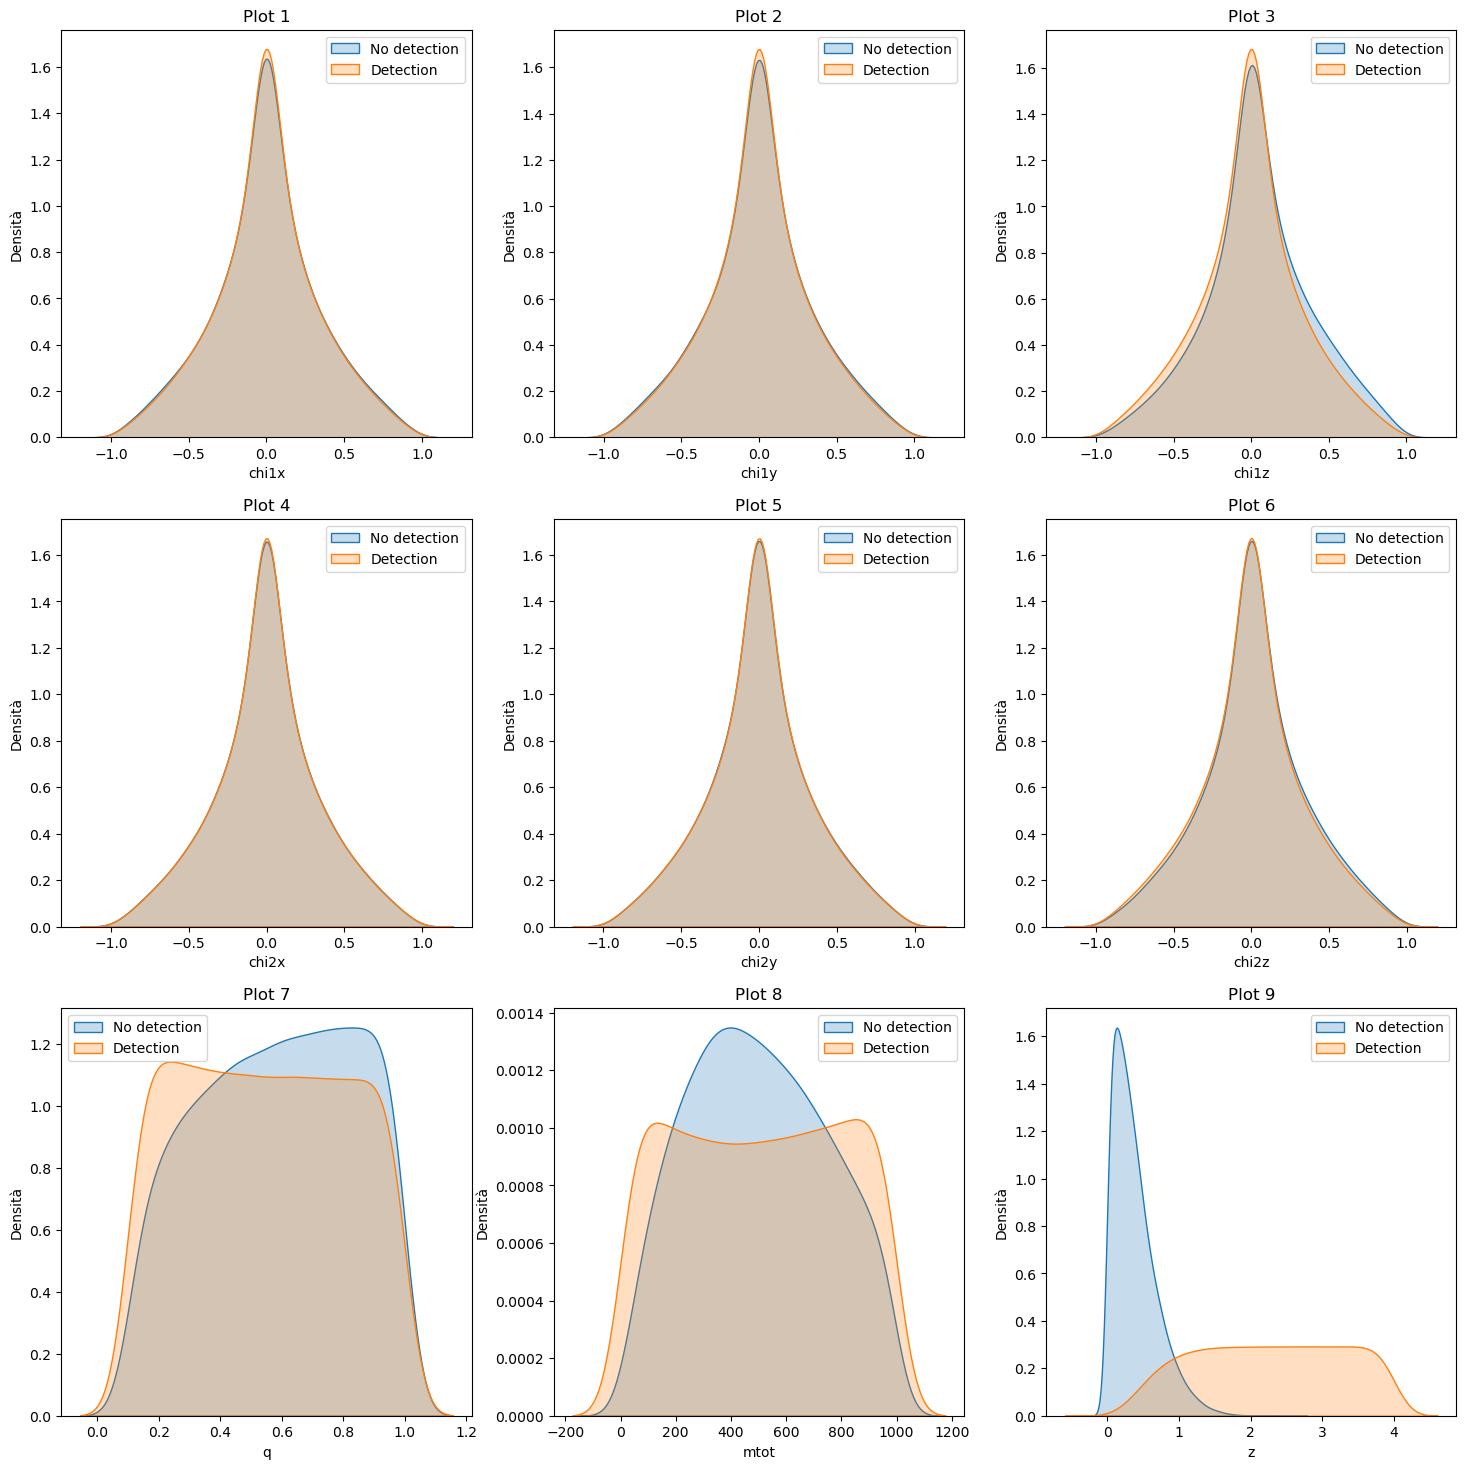

In [8]:
fig, ax = plt.subplots(3,3, figsize=(18, 18))
ax = ax.flatten()

sub_feat = ['chi1x', 'chi1y', 'chi1z', 'chi2x', 'chi2y', 'chi2z', 'q', 'mtot', 'z']

for i, feat in enumerate(sub_feat):
    sns.kdeplot(df[feat][df['det'] == 1][::10], cmap='Blues', fill=True, bw_method=0.2, ax=ax[i], label = "No detection")
    sns.kdeplot(df[feat][df['det'] == 0][::10], cmap='Reds', fill=True, bw_method=0.2, ax=ax[i], label = "Detection")
    ax[i].set_title(f'Plot {i+1}')
    ax[i].set_xlabel(feat)
    ax[i].set_ylabel('Densità')
    ax[i].legend()

I'll say that the angular momentum are useless